# 04 · The reporting gap: do limited-English tracts file fewer 311 requests?

**Question:** given how many households a tract has and what kind of housing it has, do tracts with more limited-English households file fewer 311 requests? If so, the city's data may hide real problems because some residents can't easily report them.

**Important:** fewer requests could mean fewer *problems*, not under-reporting. We have no direct measure of neighborhood conditions, so any gap we find is evidence of a *possible* reporting gap, not proof.

In [2]:
import duckdb, numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
import statsmodels.api as sm, statsmodels.formula.api as smf
pd.set_option("display.max_columns", 50, "display.width", 150)
PROC, RAW = "../data/processed", "../data/raw"
con = duckdb.connect()

## 1. Build the tract-level dataset
One row per City-of-LA tract (at least 100 households, known income). For each tract we count **resident-reported** requests (driver self-reports are filed by city staff, not residents, so they say nothing about who is able to report). We split requests into two groups, because they mean different things:

| Group | Request types | Why separate |
|---|---|---|
| **Problem reports** | graffiti, illegal dumping, homeless encampment, streetlights, dead animal | A neighbor notices something wrong and reports it. This is the cleanest test of "can people report problems?" |
| **Household service requests** | bulky items, appliances, e-waste | A resident asks for a pickup of their own items. Depends on housing type and whether a building has private hauling |

In [3]:
PROBLEM = ["Graffiti Removal","Illegal Dumping Pickup","Homeless Encampment","Multiple Streetlight Issue","Single Streetlight Issue","Dead Animal Removal"]
SERVICE = ["Bulky Items","Metal/Household Appliances","Electronic Waste"]
counts = con.sql(f"""
SELECT t.geoid,
  count(*) FILTER (WHERE NOT r.is_driver_report AND r.request_type IN {tuple(PROBLEM)}) AS n_problem,
  count(*) FILTER (WHERE NOT r.is_driver_report AND r.request_type IN {tuple(SERVICE)})  AS n_service,
  count(*) FILTER (WHERE NOT r.is_driver_report AND r.request_type IN {tuple(PROBLEM+SERVICE)}) AS n_resident,
  count(*) FILTER (WHERE r.request_type IN {tuple(PROBLEM+SERVICE)}) AS n_incl_driver,
  mode(r.council_district) AS council_district
FROM '{PROC}/requests_clean.parquet' r JOIN '{PROC}/request_tract.parquet' t USING (sr_number)
WHERE t.in_city_tract AND NOT r.bad_dates AND NOT r.is_cancelled
GROUP BY 1
""").df()

tc = pd.read_parquet(f"{PROC}/tracts_city.parquet")
acs = pd.read_csv(f"{RAW}/acs5_2023_la_tracts.csv", dtype={"geoid": str})
num = acs.select_dtypes("number").columns
acs[num] = acs[num].mask(acs[num] < -1e8)                       # Census 'no data' codes (see notebook 2)
acs["old_housing"] = (acs.B25034_009E + acs.B25034_010E + acs.B25034_011E) / acs.B25034_001E   # built before 1960
acs["lep_person"] = acs.S1601_C05_001E / acs.S1601_C01_001E     # persons 5+ speaking English < 'very well'
land = gpd.read_file(f"{RAW}/tl_2023_06_tract/tl_2023_06_tract.shp")[["GEOID","ALAND"]]

t = (tc[["geoid","frac_in_city","households","lep_share","median_income","renter_share","population"]]
       .merge(acs[["geoid","old_housing","lep_person"]], on="geoid")
       .merge(land, left_on="geoid", right_on="GEOID").drop(columns="GEOID")
       .merge(counts, on="geoid"))
t["density"] = t.population / (t.ALAND / 1e6)                   # people per km2 of land
t = t[(t.households >= 100) & t.median_income.notna() & t.old_housing.notna()].copy()
t["lep10"] = t.lep_share * 10
t["lep_person10"] = t.lep_person * 10
t["log_inc"] = np.log(t.median_income / 1000)
t["log_density"] = np.log(t.density)
t["log_hh"] = np.log(t.households)
t["quintile"] = pd.qcut(t.lep_share, 5, labels=[1,2,3,4,5]).astype(int)
print(len(t), "tracts |", int(t.n_resident.sum()), "resident requests |", int(t.households.sum()), "households")
t[["households","n_resident","n_problem","n_service","lep_share","median_income","renter_share","old_housing","density"]].describe().round(2)

1091 tracts | 3406071 resident requests | 1412544 households


,households,n_resident,n_problem,n_service,lep_share,median_income,renter_share,old_housing,density
count,1091.00,1091.00,1091.00,1091.00,1091.00,1091.00,1091.00,1091.00,1091.00
mean,1294.72,3121.97,1001.38,2120.59,0.15,87186.74,0.63,0.47,6730.75
std,463.86,1307.56,655.60,968.54,0.11,41147.99,0.26,0.22,5394.62
min,177.00,56.00,21.00,2.00,0.00,7000.00,0.02,0.00,214.11
25%,967.00,2260.00,537.50,1449.50,0.05,57706.50,0.44,0.30,3304.64
50%,1243.00,3026.00,864.00,2051.00,0.12,78750.00,0.67,0.48,5467.34
75%,1564.00,3929.50,1355.50,2728.50,0.22,106583.00,0.84,0.64,8549.67
max,4919.00,8413.00,5984.00,6324.00,0.67,250001.00,1.00,0.94,46862.89


**Check:** the tract count should match notebook 3's 1,091 tracts (the extra ACS filter on building age drops none or almost none).

In [4]:
print("tracts dropped vs notebook 3:", 1091 - len(t))
t.sort_values("n_resident", ascending=False).head(5)[["geoid","households","n_resident","lep_share","density"]]

tracts dropped vs notebook 3: 0


,geoid,households,n_resident,lep_share,density
597,06037113303,1355,8413,0.061255,929.180044
1007,06037238000,2219,8144,0.016224,3268.869637
415,06037125310,2100,7729,0.036667,3956.416796
1009,06037238200,2208,7522,0.063859,6649.906344
977,06037226002,1209,7249,0.073615,729.263397


## 2. Look at the rates first
Before any model, the simple version: requests per household per year, by limited-English quintile. We compute **total requests ÷ total households** in each quintile (not the average of the tract rates) so that big tracts count more than small ones.

In [5]:
YEARS = 3
q = t.groupby("quintile").agg(tracts=("geoid","size"), households=("households","sum"),
        resident=("n_resident","sum"), problem=("n_problem","sum"), service=("n_service","sum"),
        lep_min=("lep_share","min"), lep_max=("lep_share","max"))
for c in ["resident","problem","service"]:
    q[f"{c}_per_hh_yr"] = q[c] / q.households / YEARS
q.round(3)

,tracts,households,resident,problem,service,lep_min,lep_max,resident_per_hh_yr,problem_per_hh_yr,service_per_hh_yr
quintile,,,,,,,,,,
1,219,310441,634058,152248,481810,0.000,0.043,0.681,0.163,0.517
2,218,306569,736982,200841,536141,0.044,0.093,0.801,0.218,0.583
3,218,276070,692550,214375,478175,0.093,0.154,0.836,0.259,0.577
4,218,260596,686180,243646,442534,0.154,0.241,0.878,0.312,0.566
5,218,258868,656301,281393,374908,0.241,0.674,0.845,0.362,0.483


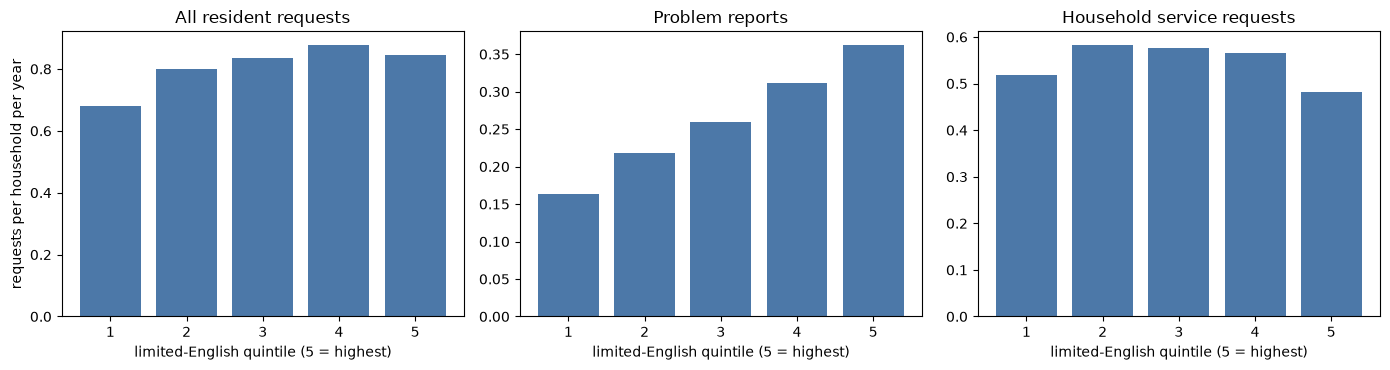

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), sharex=True)
for a, c, title in zip(ax, ["resident","problem","service"], ["All resident requests","Problem reports","Household service requests"]):
    a.bar(q.index, q[f"{c}_per_hh_yr"], color="#4c78a8"); a.set_title(title); a.set_xlabel("limited-English quintile (5 = highest)")
ax[0].set_ylabel("requests per household per year")
plt.tight_layout(); plt.show()

### What the simple rates say
- **All resident requests:** 0.68 per household per year in the lowest limited-English quintile (Q1) versus 0.85 in the highest (Q5), so Q5 files about **24% more**, not fewer.
- **Problem reports** (graffiti, dumping, encampments, streetlights) rise steadily across the quintiles, from 0.16 to 0.36 per household per year. That is more than double.
- **Household service requests** (bulky items, appliances, e-waste) go the other way slightly: 0.52 in Q1, a peak of 0.58 in Q2, and 0.48 in Q5.

So the first look does **not** show the pattern the reporting-gap hypothesis predicts. The next question is whether that holds up once housing and income are held fixed.

## 3. The regression

**Why a negative binomial?** Since the data is overdispersed 
The coefficient `b1` is converted to an **incidence rate ratio** (IRR = exp(b1·1)): per +10 points of limited-English share, requests per household change by (IRR − 1) × 100%. Standard errors are robust to unequal variance.

Controls: median income (log), renter share, share of housing built before 1960, population density (log).

In [8]:
CONTROLS = "log_inc + renter_share + old_housing + log_density"

pois = smf.glm(f"n_resident ~ lep10 + {CONTROLS}", t,
               family=sm.families.Poisson(), offset=t.log_hh).fit()
print("Pearson dispersion:", round(pois.pearson_chi2 / pois.df_resid, 1))

Pearson dispersion: 329.4


**Why a negative binomial?** The outcome is a count, so the standard choices are Poisson or negative binomial. Poisson assumes the variance equals the mean (a dispersion of 1). I fitted a Poisson model and measured its dispersion: 329, meaning the counts are about 329 times more spread out than Poisson allows. I therefore use the negative binomial, which adds a parameter (alpha) for this extra spread.

In [6]:
CONTROLS = "log_inc + renter_share + old_housing + log_density"

def fit_nb(d, y="n_resident", lep="lep10", controls=CONTROLS, family="nb", groups=None):
    f = f"{y} ~ {lep} + {controls}"
    model = (smf.negativebinomial(f, d, offset=d.log_hh) if family == "nb"
             else smf.poisson(f, d, offset=d.log_hh))
    cov = dict(cov_type="cluster", cov_kwds={"groups": groups}) if groups is not None else dict(cov_type="HC1")
    m = model.fit(disp=0, maxiter=200, **cov)           # HC1 = standard errors robust to unequal variance
    b, se = m.params[lep], m.bse[lep]
    return m, dict(irr=np.exp(b), pct=100*(np.exp(b)-1), ci_low=100*(np.exp(b-1.96*se)-1),
                   ci_high=100*(np.exp(b+1.96*se)-1), p=m.pvalues[lep], n=int(m.nobs))

m_all, r_all = fit_nb(t)
print(m_all.summary().tables[1])
r_all

                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        2.9435      0.393      7.491      0.000       2.173       3.714
lep10            0.1084      0.018      6.015      0.000       0.073       0.144
log_inc         -0.2262      0.065     -3.472      0.001      -0.354      -0.099
renter_share    -0.5871      0.081     -7.287      0.000      -0.745      -0.429
old_housing      0.7567      0.052     14.470      0.000       0.654       0.859
log_density     -0.1397      0.028     -4.943      0.000      -0.195      -0.084
alpha            0.1413      0.011     12.780      0.000       0.120       0.163


{'irr': np.float64(1.1144593813235606),
 'pct': np.float64(11.445938132356059),
 'ci_low': np.float64(7.579187882264105),
 'ci_high': np.float64(15.451672118902216),
 'p': np.float64(1.7988802501750014e-09),
 'n': 1091}

In [7]:
rows = []
for label, y in [("All resident requests","n_resident"), ("Problem reports","n_problem"), ("Household service requests","n_service")]:
    _, r = fit_nb(t, y=y); rows.append(dict(outcome=label, **r))
main_tbl = pd.DataFrame(rows).round(3)
main_tbl

,outcome,irr,pct,ci_low,ci_high,p,n
0,All resident requests,1.114,11.446,7.579,15.452,0.000,1091
1,Problem reports,1.201,20.085,14.398,26.053,0.000,1091
2,Household service requests,1.054,5.424,1.506,9.493,0.006,1091


**Which request types drive the result?** The same model for each type separately, so a pattern in one type (say, encampments concentrated downtown) can't hide inside the total.

In [8]:
by_type = con.sql(f"""
SELECT t.geoid, r.request_type, count(*) AS n
FROM '{PROC}/requests_clean.parquet' r JOIN '{PROC}/request_tract.parquet' t USING (sr_number)
WHERE t.in_city_tract AND NOT r.bad_dates AND NOT r.is_cancelled AND NOT r.is_driver_report
GROUP BY 1, 2
""").df().pivot(index="geoid", columns="request_type", values="n").fillna(0).reset_index()
tt = t.merge(by_type, on="geoid", how="left")
rows = []
for rt in PROBLEM + SERVICE:
    tt[rt.replace(" ", "_").replace("/", "_")] = tt[rt]
    _, r = fit_nb(tt, y=rt.replace(" ", "_").replace("/", "_")); rows.append(dict(request_type=rt, **r))
type_tbl = pd.DataFrame(rows).round(3)
type_tbl

,request_type,irr,pct,ci_low,ci_high,p,n
0,Graffiti Removal,1.381,38.051,28.405,48.421,0.000,1091
1,Illegal Dumping Pickup,1.115,11.545,4.639,18.907,0.001,1091
2,Homeless Encampment,1.096,9.573,0.456,19.517,0.039,1091
3,Multiple Streetlight Issue,1.192,19.152,10.415,28.580,0.000,1091
4,Single Streetlight Issue,1.109,10.932,4.351,17.929,0.001,1091
5,Dead Animal Removal,1.082,8.242,3.287,13.436,0.001,1091
6,Bulky Items,1.059,5.945,1.927,10.121,0.003,1091
7,Metal/Household Appliances,1.007,0.744,-2.683,4.292,0.675,1091
8,Electronic Waste,1.068,6.820,2.494,11.329,0.002,1091


### What the models say
- **All resident requests:** +10 points of limited-English share goes with **+11.4% more requests per household** (95% CI +7.6% to +15.5%), holding income, renter share, building age and density fixed. Across the full gap between Q1 and Q5 (about 30 points), that compounds to roughly +38%.
- **Problem reports:** +20% per 10 points (CI +14% to +26%). **Household service requests:** +5% (CI +2% to +9%).
- **By type:** the largest effect is graffiti (+38% per 10 points, CI +28% to +48%). Streetlights (+11% to +19%), illegal dumping (+12%), encampments (+10%), dead animals (+8%), bulky items (+6%) and e-waste (+7%) are all positive. Appliances show no difference (+0.7%, not significant).
- **Controls behave sensibly:** tracts with older housing file more requests (the building-age coefficient is large and positive), while higher income, more renters and higher density go with fewer requests per household. `alpha` = 0.14 confirms the counts are more spread out than Poisson allows, so the negative binomial is the right choice.

**How to read this honestly.** The direction is the *opposite* of the reporting-gap hypothesis: limited-English tracts file more per household, not fewer. That doesn't prove nobody there is under-reporting, for two reasons: (1) we cannot measure how many real problems each tract has, and graffiti and dumping are plausibly more common in dense, older, central neighborhoods than our controls capture; (2) tract averages hide differences between households inside a tract (the ecological problem). What the data **do** rule out is a large tract-level shortfall of the kind the hypothesis predicted.

## 4. Sensitivity checks
| Variant | What changes |
|---|---|
| Main | negative binomial, resident requests, four controls |
| Poisson | different count model (should agree) |
| Person-level language measure | % of persons 5+ speaking English less than "very well" instead of household share |
| Fewer controls | income only (does adding housing change the answer?) |
| Drop top 1% busiest tracts | downtown and industrial tracts file requests that aren't tied to residents |
| Tracts ≥ 90% in city | drops tracts straddling the city boundary |
| Include driver reports | the artifact we excluded |
| Cluster by council district | neighboring tracts are not independent (only ~15 clusters, so treat as rough) |

In [9]:
rate = t.n_resident / t.households
variants = {
 "Main": dict(d=t),
 "Poisson": dict(d=t, family="poisson"),
 "Person-level language measure": dict(d=t, lep="lep_person10"),
 "Fewer controls (income only)": dict(d=t, controls="log_inc"),
 "Drop top 1% busiest tracts": dict(d=t[rate <= rate.quantile(.99)]),
 "Tracts >= 90% in city": dict(d=t[t.frac_in_city >= 0.9]),
 "Include driver reports": dict(d=t, y="n_incl_driver"),
}
rows = []
for name, kw in variants.items():
    _, r = fit_nb(**kw); rows.append(dict(variant=name, **r))
d = t.copy(); d["cd"] = d.council_district.astype(str)
_, r = fit_nb(d, groups=d.cd.astype("category").cat.codes); rows.append(dict(variant="Cluster by council district", **r))
sens = pd.DataFrame(rows).round(3)
sens

,variant,irr,pct,ci_low,ci_high,p,n
0,Main,1.114,11.446,7.579,15.452,0.0,1091
1,Poisson,1.090,8.974,5.738,12.310,0.0,1091
2,Person-level language measure,1.159,15.860,13.139,18.647,0.0,1091
3,Fewer controls (income only),1.078,7.765,3.753,11.932,0.0,1091
4,Drop top 1% busiest tracts,1.109,10.930,7.103,14.894,0.0,1080
5,Tracts >= 90% in city,1.114,11.439,7.570,15.447,0.0,1085
6,Include driver reports,1.132,13.197,8.949,17.611,0.0,1091
7,Cluster by council district,1.114,11.446,5.219,18.041,0.0,1091


### What the sensitivity checks say
What the sensitivity checks say: I repeated the analysis seven ways, changing one choice at a time (the count model, the language measure, the controls, which tracts are included, and how uncertainty is calculated). Every version shows limited-English tracts filing more requests per household, by about 8% to 16% per 10 points. None produces a negative effect, so the main result does not depend on any single choice.

## 5. How do residents report?
Maybe the channel matters: do high limited-English tracts rely more on the phone and less on the app or the web? This is descriptive (it doesn't test a hypothesis), but it tells an outreach team which channel to improve.

In [10]:
con.register("tq", t[["geoid","quintile"]])
src = con.sql(f"""
SELECT tq.quintile, r.request_source AS source, count(*) AS n
FROM '{PROC}/requests_clean.parquet' r JOIN '{PROC}/request_tract.parquet' t USING (sr_number) JOIN tq USING (geoid)
WHERE t.in_city_tract AND NOT r.bad_dates AND NOT r.is_cancelled AND NOT r.is_driver_report
GROUP BY 1, 2
""").df()
mix = src.pivot(index="quintile", columns="source", values="n").fillna(0)
mix = mix.div(mix.sum(axis=1), axis=0)[["Call","Mobile App","Self Service"]].assign(other=lambda x: 1 - x.sum(axis=1))
mix.round(3)

source,Call,Mobile App,Self Service,other
quintile,,,,
1,0.491,0.314,0.192,0.003
2,0.478,0.333,0.185,0.004
3,0.464,0.358,0.174,0.004
4,0.456,0.376,0.162,0.006
5,0.390,0.424,0.179,0.006


### What the channel table says
The phone share falls as limited-English share rises (49% of requests in Q1 to 39% in Q5), while the mobile-app share rises (31% to 42%); the web self-service share is roughly flat. That is not the pattern you'd expect if limited-English residents depended on the phone line. A plausible reading is that the app, which uses photos and a map, needs less English than a phone call. We can't tell from tract data who is using which channel, so this is a lead for outreach teams to investigate and not a finding.

## 6. Which tracts have fewer requests than expected?
For the recommendation we want a list of tracts to prioritize. We fit the model **without** the language variable to get the number of requests we'd *expect* from a tract's size and housing, then compare with what was observed. A tract with a low observed/expected ratio files fewer requests than similar tracts do.

In [11]:
m0 = smf.negativebinomial(f"n_resident ~ {CONTROLS}", t, offset=t.log_hh).fit(disp=0, maxiter=200)
t["expected"] = m0.predict(t, offset=t.log_hh)
t["obs_exp"] = t.n_resident / t.expected
top = t[t.quintile == 5]
print("Top limited-English quintile: median observed/expected =", round(top.obs_exp.median(), 2),
      "| other quintiles:", round(t[t.quintile < 5].obs_exp.median(), 2))
low = top[top.obs_exp <= t.obs_exp.quantile(.25)].sort_values("obs_exp")
print(len(low), "top-quintile tracts fall in the lowest quarter of observed/expected")
print((top.obs_exp < 0.5).sum(), "top-quintile tracts have observed/expected below 0.5")
low[["geoid","households","lep_share","n_resident","expected","obs_exp"]].head(10).round(2)

Top limited-English quintile: median observed/expected = 1.07 | other quintiles: 0.97
46 top-quintile tracts fall in the lowest quarter of observed/expected
10 top-quintile tracts have observed/expected below 0.5


,geoid,households,lep_share,n_resident,expected,obs_exp
1,06037205110,866,0.32,140,2446.66,0.06
244,06037224702,718,0.25,415,2455.04,0.17
982,06037207502,2563,0.47,1193,6235.18,0.19
252,06037206202,1136,0.47,949,3566.09,0.27
1032,06037224420,894,0.56,1198,3501.90,0.34
755,06037212203,1490,0.46,1153,3089.44,0.37
209,06037139506,1503,0.26,1343,3257.60,0.41
292,06037265702,1546,0.26,1252,2996.12,0.42
230,06037139505,1544,0.32,1322,3043.26,0.43
775,06037208904,1367,0.67,1520,3336.48,0.46


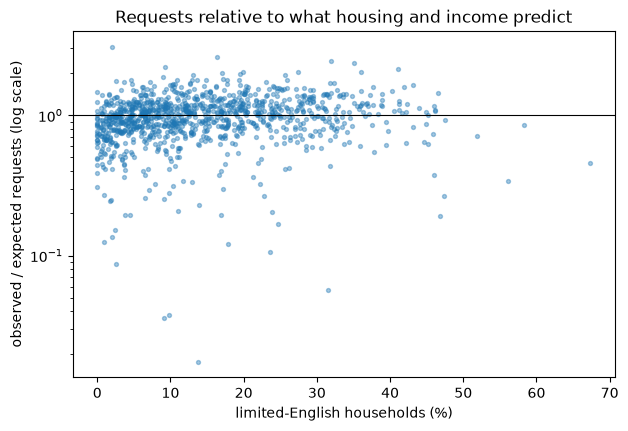

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(t.lep_share*100, t.obs_exp, s=8, alpha=.4)
ax.axhline(1, color="k", lw=.8); ax.set_yscale("log")
ax.set_xlabel("limited-English households (%)"); ax.set_ylabel("observed / expected requests (log scale)")
ax.set_title("Requests relative to what housing and income predict")
plt.show()

## 7. Save for the dashboard and write-up

In [13]:
t.to_csv(f"{PROC}/tract_reporting_gap.csv", index=False)
main_tbl.to_csv(f"{PROC}/results_gap_main.csv", index=False)
sens.to_csv(f"{PROC}/results_gap_sensitivity.csv", index=False)
q.to_csv(f"{PROC}/results_gap_quintiles.csv")
print("saved")

saved


## Findings:
For comparable tracts, those with more limited-English households filed **more**, not fewer, resident-reported 311 requests per household: about **11% more per 10 points** of limited-English share, and roughly a third more for the highest-share tracts compared with the lowest. The pattern holds across request types (strongest for graffiti), across every sensitivity check, and with the person-level language measure. We therefore find **no evidence of a tract-level reporting gap**. Residents of these tracts do use the system, and mostly through the app and less by phone.

**Individual tracts still stand out** To find tracts that file less than similar tracts, we fit the model without language to get each tract’s expected requests, then compared with the actual count. Among the 218 highest limited-English tracts, 46 are in the bottom quarter of all tracts on this measure (about what chance would give), and 10 file under half of what is expected. These are candidates for a closer look, not proof of a reporting barrier: a tract may be unusual in land use or population.

**Limits to state:** (1) no direct measure of real conditions, so "more requests" may reflect more problems; (2) tract averages say nothing about individual households; (3) service requests such as bulky-item pickup depend on whether a building has private hauling; (4) neighboring tracts are not independent, and the clustered interval is only rough.